# Отчет по лабораторной работе №6 на тему "Линейная регрессия"

**Выполнил**: студент 3 курса группы 12002408

Рыбин Даниил Евгеньевич

**Проверил**: ассистент кафедры информационных и робототехнических систем

Пузырев Никита Сергеевич

Выполните следующие задания:

1. Откройте в файл в Google Colab (используйте собственный форк репозитория).
2. Решите задачи.
3. Сохраните результат в ваш репозиторий github в директорию ./les06
4. Создайте pull request в репозиторий https://github.com/chebotarevsa/dap-2024. Название pull request должно иметь формат "<Номер лабораторной работы>  <Номер группы> <ФИО>"
5. Сдайте работу в системе "Пегас", в отчет укажите ссылку на pull request

Набор данных Diabetes (Диабет) содержит 442 образца с 10-ю признаками: возраст, пол, индекс массы тела, средний показатель давления крови и шесть измерений сыворотки крови. Целевое значение - количественный показатель прогрессирования заболевания через год после анализов.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Извлечение данных

In [ ]:
from sklearn import datasets
diabetes = datasets.load_diabetes()

1. Выведете описание набора данных и наименование признаков.

In [ ]:
print("Описание набора данных")
print(diabetes.DESCR)

print("Наименования признаков")
for i, name in enumerate(diabetes.feature_names, 1):
    print(f"{i:2d}. {name}")

Описание набора данных
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 fea

### Подготовка данных

2. Из загруженного набора данных создайте DataFrame, содержащий как признаки, так и целевое значение. Выведите первые 5 строк набора.

In [ ]:
import pandas as pd
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

df['target'] = diabetes.target

print("Первые 5 строк набора:")
print(df.head())

Первые 5 строк набора:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


3. Выведете информацию о типах данных в наборе. Имеются ли в наборе категориальные признаки? Имеются ли в наборе данные имеющие значение null?

In [ ]:
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

print("Типы данных")
print(df.dtypes)

print("Категориальные признаки")
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Количество категориальных признаков: {len(cat_cols)}")
print(f"Список: {cat_cols if cat_cols else 'нет'}")

print("Null-значения")
print(df.isnull().sum())
total_nulls = df.isnull().sum().sum()
print(f"\nКоличество: {total_nulls}")

Типы данных
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object
Категориальные признаки
Количество категориальных признаков: 0
Список: нет
Null-значения
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Количество: 0


## Исследование данных

4. Постройте матрицу корреляции.

In [ ]:
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target
corr_matrix = df.corr()
print("Матрица корреляции")
print(corr_matrix.round(2))

Матрица корреляции
         age   sex   bmi    bp    s1    s2    s3    s4    s5    s6  target
age     1.00  0.17  0.19  0.34  0.26  0.22 -0.08  0.20  0.27  0.30    0.19
sex     0.17  1.00  0.09  0.24  0.04  0.14 -0.38  0.33  0.15  0.21    0.04
bmi     0.19  0.09  1.00  0.40  0.25  0.26 -0.37  0.41  0.45  0.39    0.59
bp      0.34  0.24  0.40  1.00  0.24  0.19 -0.18  0.26  0.39  0.39    0.44
s1      0.26  0.04  0.25  0.24  1.00  0.90  0.05  0.54  0.52  0.33    0.21
s2      0.22  0.14  0.26  0.19  0.90  1.00 -0.20  0.66  0.32  0.29    0.17
s3     -0.08 -0.38 -0.37 -0.18  0.05 -0.20  1.00 -0.74 -0.40 -0.27   -0.39
s4      0.20  0.33  0.41  0.26  0.54  0.66 -0.74  1.00  0.62  0.42    0.43
s5      0.27  0.15  0.45  0.39  0.52  0.32 -0.40  0.62  1.00  0.46    0.57
s6      0.30  0.21  0.39  0.39  0.33  0.29 -0.27  0.42  0.46  1.00    0.38
target  0.19  0.04  0.59  0.44  0.21  0.17 -0.39  0.43  0.57  0.38    1.00


5. Постройте диаграмму рассеяния целевого значение и признака, коэффициент корреляции которого с  целевым значением, самый высокий.

Признак с наибольшей корреляцией: bmi (r = 0.586)


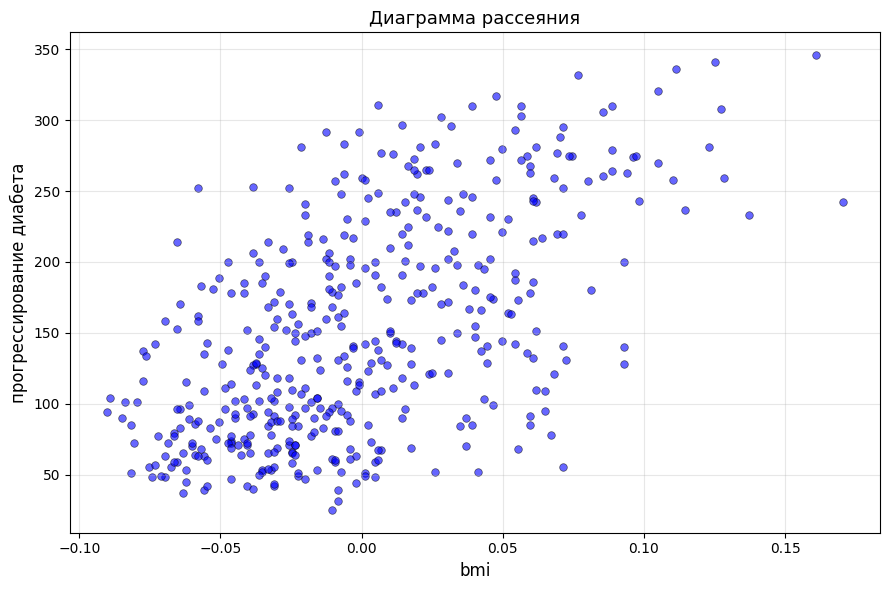

In [ ]:
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

corr_with_target = df.corr()['target'].drop('target')
best_feature = corr_with_target.abs().idxmax()
best_r = corr_with_target[best_feature]
print(f"Признак с наибольшей корреляцией: {best_feature} (r = {best_r:.3f})")

plt.figure(figsize=(9, 6))
plt.scatter(df[best_feature], df['target'],
            alpha=0.6, s=30,
            color='blue', edgecolor='black', linewidth=0.5)

plt.xlabel(f'{best_feature}', fontsize=12)
plt.ylabel('прогрессирование диабета', fontsize=12)
plt.title(f'Диаграмма рассеяния', fontsize=13)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

6. Сформируйте набор признаков (X) из 5 признаков с самым высоким коэффициентом корреляции с целевым значением. Сформируйте набор для целевого значения (y).

In [ ]:
diabetes = datasets.load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target
corr_with_target = df.corr()['target'].drop('target')
best_feature = corr_with_target.abs().idxmax()
best_r = corr_with_target[best_feature]
print(f"Признак с наибольшей корреляцией: {best_feature} (r = {best_r:.3f})")
top5_features = corr_with_target.abs().sort_values(ascending=False).head(5).index.tolist()

print("5 признаков по корреляции с самым высоким коэффициентом корреляции с целевым значением:")
print(corr_with_target[top5_features].round(3))

X = df[top5_features]
Y = df['target']

print(f"\nФорма X: {X.shape}")
print(f"Форма Y: {y.shape}")
print(f"\nX:\n{X}")
print(f"\nY:\n{Y}")

Признак с наибольшей корреляцией: bmi (r = 0.586)
5 признаков по корреляции с самым высоким коэффициентом корреляции с целевым значением:
bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s3    -0.395
Name: target, dtype: float64

Форма X: (442, 5)
Форма Y: (442,)

X:
          bmi        s5        bp        s4        s3
0    0.061696  0.019907  0.021872 -0.002592 -0.043401
1   -0.051474 -0.068332 -0.026328 -0.039493  0.074412
2    0.044451  0.002861 -0.005670 -0.002592 -0.032356
3   -0.011595  0.022688 -0.036656  0.034309 -0.036038
4   -0.036385 -0.031988  0.021872 -0.002592  0.008142
..        ...       ...       ...       ...       ...
437  0.019662  0.031193  0.059744 -0.002592 -0.028674
438 -0.015906 -0.018114 -0.067642  0.034309 -0.028674
439 -0.015906 -0.046883  0.017293 -0.011080 -0.024993
440  0.039062  0.044529  0.001215  0.026560 -0.028674
441 -0.073030 -0.004222 -0.081413 -0.039493  0.173816

[442 rows x 5 columns]

Y:
0      151.0
1       75.0
2      141.0
3      206.0
4

## Предсказательная модель

7. Разделите набор данных на два, одни для обучения модели другой для проверки. Тестовый набор должен содержать 25 процентов данных.

In [13]:
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

corr_with_target = df.corr()['target'].drop('target')
top5_features = corr_with_target.abs().sort_values(ascending=False).head(5).index.tolist()
X = df[top5_features]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

print(f"Всего данных:      X = {X.shape}, y = {y.shape}")
print(f"Обучающая выборка: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Тестовая выборка:  X_test  = {X_test.shape}, y_test  = {y_test.shape}")

print(f"Доля обучающей выборки: {len(X_train) / len(X) * 100:.1f}%")
print(f"Доля проверочной выборки:  {len(X_test) / len(X) * 100:.1f}%")

Всего данных:      X = (442, 5), y = (442,)
Обучающая выборка: X_train = (331, 5), y_train = (331,)
Тестовая выборка:  X_test  = (111, 5), y_test  = (111,)
Доля обучающей выборки: 74.9%
Доля проверочной выборки:  25.1%


8. Выполните обучение модели.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

diabetes = datasets.load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

corr_with_target = df.corr()['target'].drop('target')
top5_features = corr_with_target.abs().sort_values(ascending=False).head(5).index.tolist()
X = df[top5_features]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Обученная модель")
print(f"Свободный член: {model.intercept_:.3f}")
print("\nКоэффициенты (веса) признаков:")
for name, coef in zip(top5_features, model.coef_):
    print(f"  {name:>4s}: {coef:+.3f}")

Обученная модель
Свободный член: 151.694

Коэффициенты (веса) признаков:
   bmi: +583.874
    s5: +456.075
    bp: +331.785
    s4: -166.138
    s3: -358.641


## Проверка модели

9. Расчитайте Root mean squared error (RMSE)

In [9]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

diabetes = datasets.load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

corr_with_target = df.corr()['target'].drop('target')
top5_features = corr_with_target.abs().sort_values(ascending=False).head(5).index.tolist()
X = df[top5_features]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Оценка качества модели")
print(f"RMSE: {rmse:.3f}")

Оценка качества модели
RMSE: 53.785


10. Расчитайте R² (коэффициент детерминации)

In [12]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

diabetes = datasets.load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

corr_with_target = df.corr()['target'].drop('target')
top5_features = corr_with_target.abs().sort_values(ascending=False).head(5).index.tolist()
X = df[top5_features]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
print(f"R^2: {r2:.3f}")

R^2: 0.477


## Вопросы для защиты

**1. Какие типы машинного обучения вы знаете?**
- Обучение с учителем
- Обучение без учителя
- Полуавтоматическое обучение
- Самообучение

**2. Чем отличается обучение с учителем и без учителя?**
- С учителем: есть размеченные данные (пары «признаки-ответ»), модель учится предсказывать ответ.
- Без учителя: разметки нет, модель ищет скрытые структуры (кластеры, аномалии, сжатие).

**3. Чем пакетное обучение отличается от динамического?**
- Пакетное: модель обучается сразу на всём наборе данных, затем используется без дообучения.
- Динамическое: модель обучается постепенно, порциями данных, обновляясь по мере поступления новых.

**4. Чем обучение на основе образцов отличается от обучения на основе модели?**
- На основе образцов: запоминаем примеры и сравниваем новые с ними.
- На основе модели: строим обобщающую модель (параметры), затем по ней делаем прогноз.

**5. Что такое линейная регрессия?**

Модель, предсказывающая числовое значение как линейную комбинацию признаков. Обучается минимизацией ошибки.

**6. Что такое градиентный спуск?**

Итеративный метод оптимизации: параметры обновляются в направлении антиградиента функции потерь.

**7. Как правильно обрабатывать категориальные признаки?**
- One-Hot Encoding - для номинальных без порядка.
- Ordinal / Label Encoding - для порядковых.
- Target / Frequency Encoding - при большом числе категорий.
- Нельзя подавать строки в модель напрямую.

**8. Что такое матрица корреляции?**

Квадратная таблица коэффициентов корреляции между всеми парами признаков. Диагональ = 1, матрица симметрична. Используется для поиска связей и мультиколлинеарности.

**9. Что показывает метрика RMSE?**

Среднеквадратичную ошибку в тех же единицах, что и целевая переменная. Чувствительна к крупным ошибкам, чем меньше - тем лучше.

**10. Что показывает метрика R²?**

Долю объяснённой дисперсии целевой переменной: значение 1 - идеал, 0 - модель не лучше среднего, < 0 - модель хуже среднего.